# Linear Regression with Ridge and Lasso Regularization
**Dataset:** `Salary_Data.csv` (30 rows): `YearsExperience` → `Salary`

Steps:
1. Load and explore the data
2. Linear regression (OLS)
3. Ridge and Lasso (fixed alpha)
4. RidgeCV and LassoCV (alpha chosen by cross-validation)
5. Compare all models
6. Demo where regularization really matters (polynomial features)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

## 1. Load and explore the data

In [2]:
df = pd.read_csv("Salary_Data.csv")
print(df.shape)
print(df.isnull().sum())
df.describe()

(30, 2)
YearsExperience    0
Salary             0
dtype: int64


,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


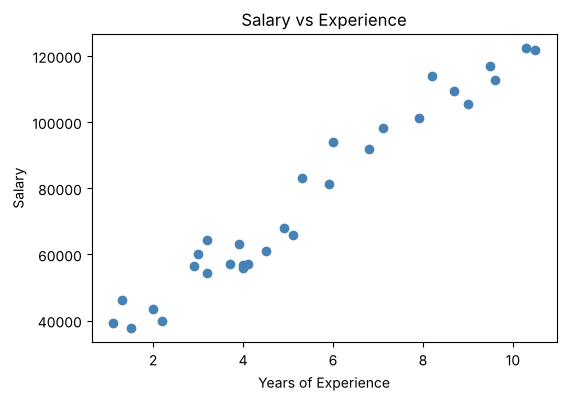

Correlation: 0.9782


In [3]:
plt.figure(figsize=(6, 4))
plt.scatter(df["YearsExperience"], df["Salary"], color="steelblue")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary vs Experience")
plt.show()

print("Correlation:", round(df["YearsExperience"].corr(df["Salary"]), 4))

## 2. Train/test split

In [4]:
X = df[["YearsExperience"]]
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)

def evaluate(model, name):
    """Return test-set metrics for a fitted model."""
    pred = model.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, pred),
    }

results = []

Train: (24, 1)  Test: (6, 1)


## 3. Linear Regression (OLS)

In [5]:
ols = LinearRegression()
ols.fit(X_train, y_train)

print("Intercept:", round(ols.intercept_, 2))
print("Slope (per year of experience):", round(ols.coef_[0], 2))
results.append(evaluate(ols, "OLS"))
pd.DataFrame(results)

Intercept: 25321.58
Slope (per year of experience): 9423.82


,Model,MAE,MSE,RMSE,R2
0,OLS,6286.453831,4.983010e+07,7059.043622,0.902446


## 4. Ridge and Lasso (fixed alpha)
Features are standardized first because the penalty depends on coefficient size.
We use a pipeline so the scaler is fit only on training data.

In [6]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge.fit(X_train, y_train)
results.append(evaluate(ridge, "Ridge (alpha=1)"))

lasso = make_pipeline(StandardScaler(), Lasso(alpha=1.0))
lasso.fit(X_train, y_train)
results.append(evaluate(lasso, "Lasso (alpha=1)"))

pd.DataFrame(results)

,Model,MAE,MSE,RMSE,R2
0,OLS,6286.453831,4.983010e+07,7059.043622,0.902446
1,Ridge (alpha=1),6192.215678,5.171076e+07,7191.019734,0.898764
2,Lasso (alpha=1),6286.367060,4.983107e+07,7059.112571,0.902444


## 5. RidgeCV and LassoCV (alpha chosen by 5-fold CV)

In [7]:
alphas = np.logspace(-3, 4, 50)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_cv = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas, cv=cv))
ridge_cv.fit(X_train, y_train)
print("RidgeCV best alpha:", ridge_cv.named_steps["ridgecv"].alpha_)
results.append(evaluate(ridge_cv, "RidgeCV"))

lasso_cv = make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=cv, max_iter=100000))
lasso_cv.fit(X_train, y_train)
print("LassoCV best alpha:", lasso_cv.named_steps["lassocv"].alpha_)
results.append(evaluate(lasso_cv, "LassoCV"))

pd.DataFrame(results)

RidgeCV best alpha: 0.7196856730011514
LassoCV best alpha: 268.26957952797216


,Model,MAE,MSE,RMSE,R2
0,OLS,6286.453831,4.983010e+07,7059.043622,0.902446
1,Ridge (alpha=1),6192.215678,5.171076e+07,7191.019734,0.898764
2,Lasso (alpha=1),6286.367060,4.983107e+07,7059.112571,0.902444
3,RidgeCV,6217.862901,5.103567e+07,7143.925253,0.900086
4,LassoCV,6263.175932,5.014134e+07,7081.055048,0.901837


## 6. Compare models
Only 6 test rows, so a single test split is noisy. We also report repeated 5-fold cross-validated RMSE on the full dataset, which is a more reliable comparison.

In [8]:
models = {
    "OLS": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge (alpha=1)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso (alpha=1)": make_pipeline(StandardScaler(), Lasso(alpha=1.0)),
    "RidgeCV": make_pipeline(StandardScaler(), RidgeCV(alphas=alphas)),
    "LassoCV": make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=5, max_iter=100000)),
}

cv_rmse = {}
for name, m in models.items():
    scores = []
    for seed in range(10):                     # repeat with different shuffles
        kf = KFold(n_splits=5, shuffle=True, random_state=seed)
        s = cross_val_score(m, X, y, cv=kf, scoring="neg_root_mean_squared_error")
        scores.extend(-s)
    cv_rmse[name] = (np.mean(scores), np.std(scores))

comparison = pd.DataFrame(results).set_index("Model")
comparison["CV RMSE (mean)"] = [cv_rmse[n][0] for n in comparison.index]
comparison["CV RMSE (std)"] = [cv_rmse[n][1] for n in comparison.index]
comparison.round(4)

,MAE,MSE,RMSE,R2,CV RMSE (mean),CV RMSE (std)
Model,,,,,,
OLS,6286.4538,4.983010e+07,7059.0436,0.9024,5863.1580,1168.3193
Ridge (alpha=1),6192.2157,5.171076e+07,7191.0197,0.8988,5932.2772,1173.2870
Lasso (alpha=1),6286.3671,4.983107e+07,7059.1126,0.9024,5863.1362,1168.2877
RidgeCV,6217.8629,5.103567e+07,7143.9253,0.9001,5854.9385,1158.4729
LassoCV,6263.1759,5.014134e+07,7081.0550,0.9018,5883.7462,1125.4953


## 7. Coefficients and intercepts (original units)

In [9]:
def original_units(pipe, est_name):
    sc = pipe.named_steps["standardscaler"]
    est = pipe.named_steps[est_name]
    slope = est.coef_[0] / sc.scale_[0]
    intercept = est.intercept_ - slope * sc.mean_[0]
    return slope, intercept

rows = [{"Model": "OLS", "Slope": ols.coef_[0], "Intercept": ols.intercept_}]
for name, pipe, est in [
    ("Ridge (alpha=1)", ridge, "ridge"),
    ("Lasso (alpha=1)", lasso, "lasso"),
    ("RidgeCV", ridge_cv, "ridgecv"),
    ("LassoCV", lasso_cv, "lassocv"),
]:
    s, i = original_units(pipe, est)
    rows.append({"Model": name, "Slope": s, "Intercept": i})

pd.DataFrame(rows).round(2)

,Model,Slope,Intercept
0,OLS,9423.82,25321.58
1,Ridge (alpha=1),9046.86,27277.02
2,Lasso (alpha=1),9423.47,25323.38
3,RidgeCV,9149.45,26744.84
4,LassoCV,9330.70,25804.60


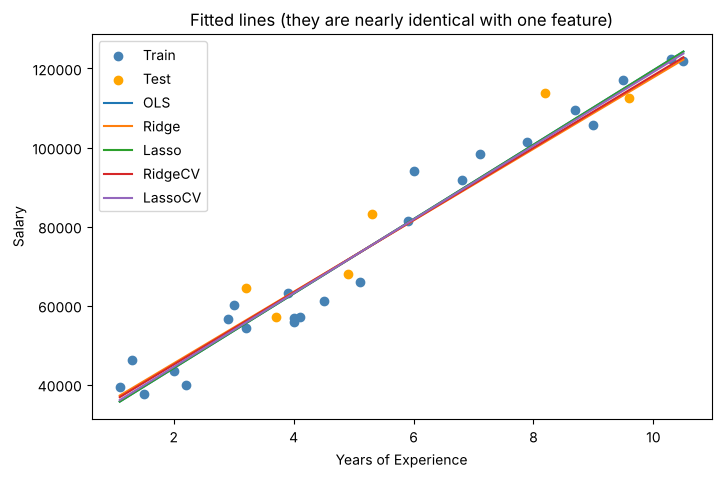

In [10]:
grid = np.linspace(X["YearsExperience"].min(), X["YearsExperience"].max(), 100).reshape(-1, 1)
grid_df = pd.DataFrame(grid, columns=["YearsExperience"])

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label="Train", color="steelblue")
plt.scatter(X_test, y_test, label="Test", color="orange")
for name, m in [("OLS", ols), ("Ridge", ridge), ("Lasso", lasso), ("RidgeCV", ridge_cv), ("LassoCV", lasso_cv)]:
    plt.plot(grid, m.predict(grid_df), label=name, linewidth=1.5)
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Fitted lines (they are nearly identical with one feature)")
plt.legend()
plt.show()

## 8. Where regularization really matters: polynomial features
With a single feature, regularization has almost nothing to shrink, so all models look alike.
To see Ridge and Lasso do their job, we add polynomial terms (x, x², ..., x⁸), which are strongly
correlated and make plain OLS prone to overfitting.

In [11]:
degree = 8
poly_models = {
    "OLS (poly)": make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), LinearRegression()),
    "Ridge (poly)": make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(),
                                  RidgeCV(alphas=alphas)),
    "Lasso (poly)": make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(),
                                  LassoCV(alphas=alphas, cv=5, max_iter=200000)),
}

poly_rows = []
for name, m in poly_models.items():
    m.fit(X_train, y_train)
    pred_tr, pred_te = m.predict(X_train), m.predict(X_test)
    scores = []
    for seed in range(10):
        kf = KFold(n_splits=5, shuffle=True, random_state=seed)
        scores.extend(-cross_val_score(m, X, y, cv=kf, scoring="neg_root_mean_squared_error"))
    poly_rows.append({
        "Model": name,
        "Train RMSE": np.sqrt(mean_squared_error(y_train, pred_tr)),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred_te)),
        "Test R2": r2_score(y_test, pred_te),
        "CV RMSE": np.mean(scores),
    })
pd.DataFrame(poly_rows).round(4)

,Model,Train RMSE,Test RMSE,Test R2,CV RMSE
0,OLS (poly),3809.0929,7467.3321,0.8908,6247.4560
1,Ridge (poly),4613.5659,6882.5818,0.9073,5938.3402
2,Lasso (poly),4594.3756,6922.7107,0.9062,6076.0597


In [12]:
coef_table = pd.DataFrame({
    "Term": [f"x^{i}" for i in range(1, degree + 1)],
    "OLS": poly_models["OLS (poly)"][-1].coef_,
    "Ridge": poly_models["Ridge (poly)"][-1].coef_,
    "Lasso": poly_models["Lasso (poly)"][-1].coef_,
})
print("Standardized coefficients (note Lasso zeroing out terms):")
print("RidgeCV alpha:", round(poly_models["Ridge (poly)"][-1].alpha_, 4))
print("LassoCV alpha:", round(poly_models["Lasso (poly)"][-1].alpha_, 4))
print("Lasso terms set to zero:", int((coef_table["Lasso"] == 0).sum()), "of", degree)
coef_table.round(2)

Standardized coefficients (note Lasso zeroing out terms):
RidgeCV alpha: 0.0139
LassoCV alpha: 10.0
Lasso terms set to zero: 4 of 8


,Term,OLS,Ridge,Lasso
0,x^1,-731941.75,7492.94,1599.85
1,x^2,6294219.14,27579.30,44841.97
2,x^3,-21837368.84,13807.66,0.00
3,x^4,34812462.81,-5491.75,-0.00
4,x^5,-15460941.27,-15982.74,-32013.57
5,x^6,-24030978.27,-14277.83,-0.00
6,x^7,32002023.47,-2467.06,-0.00
7,x^8,-11023462.53,15713.36,11865.07


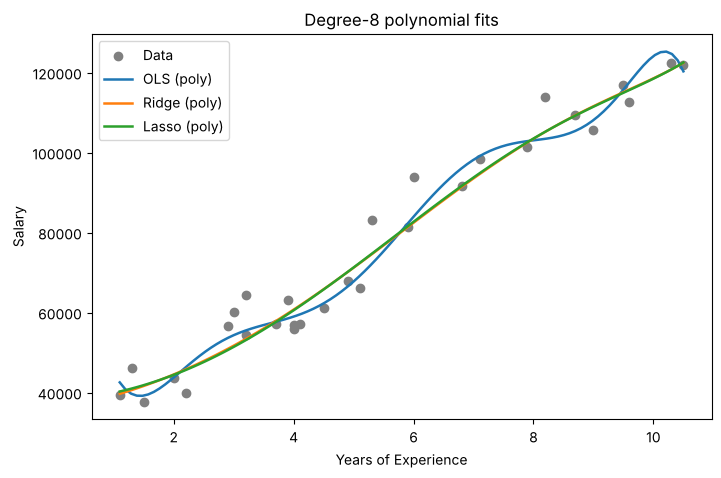

In [13]:
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color="gray", label="Data")
for name, m in poly_models.items():
    plt.plot(grid, m.predict(grid_df), label=name, linewidth=1.8)
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title(f"Degree-{degree} polynomial fits")
plt.legend()
plt.show()

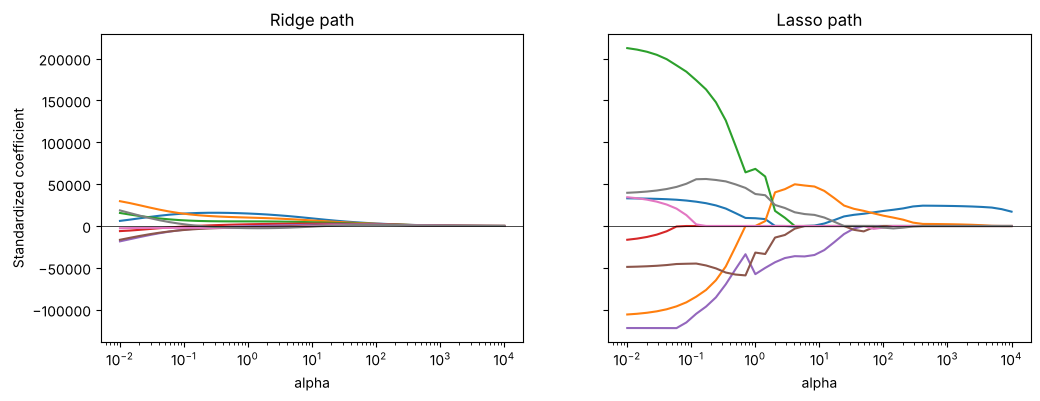

In [14]:
# Coefficient paths: how each polynomial term shrinks as alpha grows
path_alphas = np.logspace(-2, 4, 40)
scaler_poly = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler())
Xp = scaler_poly.fit_transform(X_train)

ridge_path = [Ridge(alpha=a).fit(Xp, y_train).coef_ for a in path_alphas]
lasso_path = [Lasso(alpha=a, max_iter=200000).fit(Xp, y_train).coef_ for a in path_alphas]

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax[0].plot(path_alphas, ridge_path); ax[0].set_xscale("log"); ax[0].set_title("Ridge path")
ax[1].plot(path_alphas, lasso_path); ax[1].set_xscale("log"); ax[1].set_title("Lasso path")
for a in ax:
    a.set_xlabel("alpha"); a.axhline(0, color="k", linewidth=0.5)
ax[0].set_ylabel("Standardized coefficient")
plt.show()